# PathSnap - Reproducible Candidate Ranking Model Training

This notebook trains and compares exactly five scikit-learn models:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. K-Nearest Neighbors

Training uses trip-level `GroupKFold`; the separate
`data/processed/student_test_candidates.csv` file is never used for fitting or
hyperparameter selection. The repository marks label-quality rows with
`aligned == 1`, so only aligned rows are fitted and evaluated; excluded rows
are reported.

Run every cell from top to bottom in Google Colab.

In [1]:
import json, warnings, joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    OPTUNA_AVAILABLE = True
except Exception:
    OPTUNA_AVAILABLE = False

print("Optuna available:", OPTUNA_AVAILABLE)


Optuna available: False


## 1. Load CSV files

The notebook first looks for repository paths, then offers Colab upload.
It can also load from Google Drive using the optional cell below.

In [2]:
def find_repo_csv(filename):
    path = Path("/content") / filename

    if path.exists():
        return path

    return None



TRAIN_PATH = find_repo_csv("train_candidates.csv")
TEST_PATH = find_repo_csv("student_test_candidates.csv")

if TRAIN_PATH is None:
    try:
        from google.colab import files
        print("Upload train_candidates.csv")
        uploaded = files.upload()
        TRAIN_PATH = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("train_candidates.csv was not found")

if TEST_PATH is None:
    try:
        from google.colab import files
        print("Upload student_test_candidates.csv")
        uploaded = files.upload()
        TEST_PATH = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("student_test_candidates.csv was not found")

train_full = pd.read_csv(TRAIN_PATH)
test_full = pd.read_csv(TEST_PATH)
print("Training CSV:", TRAIN_PATH, train_full.shape)
print("Student test CSV:", TEST_PATH, test_full.shape)


Training CSV: /content/train_candidates.csv (1084912, 18)
Student test CSV: /content/student_test_candidates.csv (113648, 18)


In [ ]:
# Optional Google Drive loading:
# from google.colab import drive
# drive.mount("/content/drive")
# TRAIN_PATH = Path("/content/drive/MyDrive/PathSnap/data/processed/train_candidates.csv")
# TEST_PATH = Path("/content/drive/MyDrive/PathSnap/data/processed/student_test_candidates.csv")
# train_full = pd.read_csv(TRAIN_PATH)
# test_full = pd.read_csv(TEST_PATH)


## 2. Complete data audit

The audit reports duplicates, missing/infinite values, candidate counts,
label quality, constant features, and non-numeric columns. Invalid label
counts are reported and not silently discarded.

In [3]:
REQUIRED = {
    "trip_id", "obs_idx", "timestamp", "candidate_arc_id", "distance_m",
    "heading_diff", "speed_mps", "bearing", "is_match", "projected_offset_m",
    "arc_length_m", "remaining_distance_m", "offset_ratio", "time_delta_s",
    "gps_displacement_m", "candidate_heading_deg", "heading_missing", "aligned"
}
missing_required = sorted(REQUIRED - set(train_full.columns))
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

print("=== TRAINING DATA AUDIT ===")
print("Number of rows:", len(train_full))
print("Number of columns:", train_full.shape[1])
print("Column names:", train_full.columns.tolist())
print("\nData types:")
print(train_full.dtypes.to_string())
print("\nMissing values:")
print(train_full.isna().sum().to_string())
print("Duplicate rows:", int(train_full.duplicated().sum()))
print("Duplicate candidate identities:", int(
    train_full.duplicated(["trip_id", "obs_idx", "candidate_arc_id"]).sum()
))
print("Unique trip count:", train_full["trip_id"].nunique())
print("Unique observation count:", train_full.groupby(["trip_id", "obs_idx"]).ngroups)
print("Candidate count per observation:")
print(train_full.groupby(["trip_id", "obs_idx"]).size().describe().to_string())
print("Positive and negative class counts:", train_full["is_match"].value_counts().to_dict())
print("Positive class percentage:", float(train_full["is_match"].mean() * 100))

full_labels = train_full.groupby(["trip_id", "obs_idx"])["is_match"].sum()
print("Observations with exactly one positive:", int((full_labels == 1).sum()))
print("Observations with zero positives:", int((full_labels == 0).sum()))
print("Observations with multiple positives:", int((full_labels > 1).sum()))

numeric = train_full.select_dtypes(include=[np.number])
print("Constant numeric features:", [
    c for c in numeric.columns if train_full[c].nunique(dropna=False) <= 1
])
print("Non-numeric columns:", train_full.select_dtypes(exclude=[np.number]).columns.tolist())
print("Infinite values:", int(np.isinf(numeric.to_numpy(dtype=float)).sum()))

train = train_full.loc[train_full["aligned"] == 1].copy().reset_index(drop=True)
print("\nAligned rows retained:", len(train), "of", len(train_full))
print("Unaligned rows excluded:", int((train_full["aligned"] != 1).sum()))

train_labels = train.groupby(["trip_id", "obs_idx"])["is_match"].sum()
print("Aligned observations with exactly one positive:", int((train_labels == 1).sum()))
print("Aligned observations with zero positives:", int((train_labels == 0).sum()))
print("Aligned observations with multiple positives:", int((train_labels > 1).sum()))
print("Aligned duplicate candidate identities:", int(
    train.duplicated(["trip_id", "obs_idx", "candidate_arc_id"]).sum()
))


=== TRAINING DATA AUDIT ===
Number of rows: 1084912
Number of columns: 18
Column names: ['trip_id', 'obs_idx', 'timestamp', 'candidate_arc_id', 'distance_m', 'heading_diff', 'speed_mps', 'bearing', 'is_match', 'projected_offset_m', 'arc_length_m', 'remaining_distance_m', 'offset_ratio', 'time_delta_s', 'gps_displacement_m', 'candidate_heading_deg', 'heading_missing', 'aligned']

Data types:
trip_id                    int64
obs_idx                    int64
timestamp                float64
candidate_arc_id           int64
distance_m               float64
heading_diff             float64
speed_mps                float64
bearing                  float64
is_match                   int64
projected_offset_m       float64
arc_length_m             float64
remaining_distance_m     float64
offset_ratio             float64
time_delta_s             float64
gps_displacement_m       float64
candidate_heading_deg    float64
heading_missing            int64
aligned                    int64

Missing val

## 3. Features and leakage protection

Only predictive geometric, directional, and movement features are included.
Trip, observation, candidate, timestamp, target, and alignment columns are
excluded from the feature matrix.

In [4]:
FEATURE_COLUMNS = [
    "distance_m", "heading_diff", "speed_mps", "bearing",
    "projected_offset_m", "arc_length_m", "remaining_distance_m",
    "offset_ratio", "time_delta_s", "gps_displacement_m",
    "candidate_heading_deg", "heading_missing"
]
TARGET = "is_match"
IDENTIFIERS = ["trip_id", "obs_idx", "candidate_arc_id"]

for name, df in [("train", train), ("student_test", test_full)]:
    missing = [c for c in FEATURE_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"{name} missing features: {missing}")

train_test = test_full.loc[test_full["aligned"] == 1].copy().reset_index(drop=True)
X = train[FEATURE_COLUMNS].copy()
y = train[TARGET].astype(int)
groups = train["trip_id"].astype(str)
X_test = train_test[FEATURE_COLUMNS].copy()
y_test = train_test[TARGET].astype(int)

leakage = set(FEATURE_COLUMNS).intersection(
    {TARGET, "trip_id", "obs_idx", "candidate_arc_id", "timestamp", "aligned"}
)
if leakage:
    raise AssertionError(f"Target or identifier leakage: {sorted(leakage)}")

print("Feature matrix:", X.shape)
print("Features:", FEATURE_COLUMNS)
print("Training trips:", groups.nunique())
print("Student test aligned rows:", len(train_test))


Feature matrix: (1049122, 12)
Features: ['distance_m', 'heading_diff', 'speed_mps', 'bearing', 'projected_offset_m', 'arc_length_m', 'remaining_distance_m', 'offset_ratio', 'time_delta_s', 'gps_displacement_m', 'candidate_heading_deg', 'heading_missing']
Training trips: 80
Student test aligned rows: 113220


## 4. Shared five-fold trip GroupKFold

Five folds are used if 80 trips are available and the folds preserve both
classes. Every model receives exactly these same fold indices.

In [5]:
unique_trips = groups.nunique()
n_splits = 5 if unique_trips >= 5 else min(unique_trips, 3)
if n_splits < 2:
    raise ValueError("At least two training trips are required")

cv = GroupKFold(n_splits=n_splits)
cv_splits = list(cv.split(X, y, groups=groups))

for fold, (train_idx, valid_idx) in enumerate(cv_splits, 1):
    train_trips = set(groups.iloc[train_idx])
    valid_trips = set(groups.iloc[valid_idx])
    overlap = train_trips & valid_trips
    print(
        f"Fold {fold}: train={len(train_idx)} rows/{len(train_trips)} trips, "
        f"valid={len(valid_idx)} rows/{len(valid_trips)} trips, "
        f"train classes={np.bincount(y.iloc[train_idx], minlength=2).tolist()}, "
        f"valid classes={np.bincount(y.iloc[valid_idx], minlength=2).tolist()}, "
        f"overlap={len(overlap)}"
    )
    if overlap:
        raise AssertionError("Trip leakage between folds")


Fold 1: train=839755 rows/65 trips, valid=209367 rows/15 trips, train classes=[694579, 145176], valid classes=[170744, 38623], overlap=0
Fold 2: train=839573 rows/64 trips, valid=209549 rows/16 trips, train classes=[687498, 152075], valid classes=[177825, 31724], overlap=0
Fold 3: train=839705 rows/64 trips, valid=209417 rows/16 trips, train classes=[699249, 140456], valid classes=[166074, 43343], overlap=0
Fold 4: train=839808 rows/64 trips, valid=209314 rows/16 trips, train classes=[691847, 147961], valid classes=[173476, 35838], overlap=0
Fold 5: train=837647 rows/63 trips, valid=211475 rows/17 trips, train classes=[688119, 149528], valid classes=[177204, 34271], overlap=0


## 5. Pipelines and evaluation utilities

Preprocessing is fitted only inside each fold. Raw positive-class probabilities
are used for ranking; normalized probabilities are only used as HMM emissions.

In [6]:
def scaled_pipeline(estimator):
    return Pipeline([
        ("preprocess", Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler())
        ])),
        ("model", estimator)
    ])


def tree_pipeline(estimator):
    return Pipeline([
        ("preprocess", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("model", estimator)
    ])


def positive_probability(model, X_data):
    proba = model.predict_proba(X_data)
    if hasattr(model, "named_steps"):
        classes = model.named_steps["model"].classes_
    else:
        classes = model.classes_
    return proba[:, list(classes).index(1)]


def ranking_metrics(frame):
    top1_correct = 0
    top3_correct = 0
    reciprocal_ranks = []

    for _, group in frame.groupby(["trip_id", "obs_idx"]):
        if int(group["is_match"].sum()) != 1:
            continue
        ranked = group.sort_values("raw_probability", ascending=False)
        rank = int(np.where(ranked["is_match"].to_numpy() == 1)[0][0] + 1)
        top1_correct += int(rank == 1)
        top3_correct += int(rank <= 3)
        reciprocal_ranks.append(1.0 / rank)

    if not reciprocal_ranks:
        return {"Top-1 Accuracy": np.nan, "Top-3 Recall": np.nan, "MRR": np.nan}
    n = len(reciprocal_ranks)
    return {
        "Top-1 Accuracy": top1_correct / n,
        "Top-3 Recall": top3_correct / n,
        "MRR": float(np.mean(reciprocal_ranks)),
    }


def evaluate(name, y_true, raw_probability, ranking_frame):
    y_pred = (raw_probability >= 0.5).astype(int)
    out = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Log Loss": log_loss(y_true, raw_probability, labels=[0, 1]),
        "Confusion Matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]),
    }
    try:
        out["ROC-AUC"] = roc_auc_score(y_true, raw_probability)
    except ValueError:
        out["ROC-AUC"] = np.nan
    try:
        out["PR-AUC / AP"] = average_precision_score(y_true, raw_probability)
    except ValueError:
        out["PR-AUC / AP"] = np.nan
    out.update(ranking_metrics(ranking_frame))
    return out


def predict_normalized(model, candidate_df):
    raw = positive_probability(model, candidate_df[FEATURE_COLUMNS])
    out = candidate_df[IDENTIFIERS].copy()
    out["raw_probability"] = raw
    out["probability"] = raw
    out["probability"] = out.groupby(["trip_id", "obs_idx"])["probability"].transform(
        lambda s: s / s.sum() if s.sum() > 0 else np.ones(len(s)) / len(s)
    )
    return out


## 6. Baseline training

All five baselines use the exact same features and fold indices.

In [7]:
model_specs = {
    "Logistic Regression": scaled_pipeline(
        LogisticRegression(max_iter=2000, class_weight="balanced", solver="lbfgs", random_state=42)),
    "Decision Tree": tree_pipeline(
        DecisionTreeClassifier(random_state=42, class_weight="balanced")),
    "Random Forest": tree_pipeline(
        RandomForestClassifier(n_estimators=100, random_state=42,
                               class_weight="balanced_subsample", n_jobs=-1)),
    "Gradient Boosting": tree_pipeline(
        GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                   max_depth=3, random_state=42)),
    "KNN": scaled_pipeline(
        KNeighborsClassifier(n_neighbors=15, weights="distance",
                             metric="euclidean", n_jobs=-1)),
}

baseline_oof = {}
baseline_metrics = []

for name, pipeline in model_specs.items():
    print("Baseline:", name)
    oof = np.zeros(len(train), dtype=float)
    for train_idx, valid_idx in cv_splits:
        fold_model = clone(pipeline)
        fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])
        oof[valid_idx] = positive_probability(fold_model, X.iloc[valid_idx])
    baseline_oof[name] = oof
    ranking_frame = train[["trip_id", "obs_idx", "is_match"]].copy()
    ranking_frame["raw_probability"] = oof
    baseline_metrics.append(evaluate(name, y.to_numpy(), oof, ranking_frame))

baseline_table = pd.DataFrame([
    {k: v for k, v in m.items() if k != "Confusion Matrix"}
    for m in baseline_metrics
]).sort_values(["Top-1 Accuracy", "MRR", "PR-AUC / AP"], ascending=False)
print("\nBaseline comparison:")
print(baseline_table.to_string(index=False))


Baseline: Logistic Regression
Baseline: Decision Tree
Baseline: Random Forest


KeyboardInterrupt: 

In [8]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import average_precision_score
import time

# ==========================================
# FAST GRADIENT BOOSTING HYPERPARAMETER TUNING
# ==========================================

print("Starting fast Gradient Boosting tuning...", flush=True)
start_time = time.time()

# 1. Group-based 80/20 validation split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

tune_train_idx, tune_valid_idx = next(
    splitter.split(X, y, groups=groups)
)

# Verify no trip leakage
assert set(groups.iloc[tune_train_idx]).isdisjoint(
    set(groups.iloc[tune_valid_idx])
)

# 2. Use a smaller training sample for faster tuning
rng = np.random.RandomState(42)

SAMPLE_SIZE = 50000

sample_idx = rng.choice(
    tune_train_idx,
    size=min(SAMPLE_SIZE, len(tune_train_idx)),
    replace=False
)

X_tune = X.iloc[sample_idx]
y_tune = y.iloc[sample_idx]

X_valid = X.iloc[tune_valid_idx]
y_valid = y.iloc[tune_valid_idx]

print("Tuning sample:", X_tune.shape)
print("Validation sample:", X_valid.shape)

# 3. Three compact parameter configurations
configs = [
    {
        "n_estimators": 50,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_samples_leaf": 20,
        "subsample": 0.8
    },
    {
        "n_estimators": 70,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_samples_leaf": 10,
        "subsample": 0.8
    },
    {
        "n_estimators": 50,
        "learning_rate": 0.1,
        "max_depth": 3,
        "min_samples_leaf": 20,
        "subsample": 0.8
    }
]

results = []
best_score = -1
best_model = None

# 4. Evaluate each configuration
for i, params in enumerate(configs, 1):

    print(f"\nTrial {i}/{len(configs)}: {params}", flush=True)

    model = tree_pipeline(
        GradientBoostingClassifier(
            **params,
            random_state=42
        )
    )

    model.fit(X_tune, y_tune)

    probabilities = positive_probability(model, X_valid)

    score = average_precision_score(
        y_valid,
        probabilities
    )

    print(f"Validation PR-AUC: {score:.5f}", flush=True)

    results.append({
        "Model": "Gradient Boosting",
        "Trial": i,
        "PR-AUC": score,
        **params
    })

    if score > best_score:
        best_score = score
        best_model = model

# 5. Store selected model
best_name = "Gradient Boosting"

tuned_pipelines = {
    best_name: best_model
}

search_summary = results

# 6. Evaluate selected model on complete validation groups
best_probabilities = positive_probability(
    best_model, X_valid
)

ranking_frame = train.iloc[tune_valid_idx][
    ["trip_id", "obs_idx", "is_match"]
].copy()

ranking_frame["raw_probability"] = best_probabilities

best_metrics = evaluate(
    best_name,
    y_valid.to_numpy(),
    best_probabilities,
    ranking_frame
)

comparison = pd.DataFrame([
    {k: v for k, v in best_metrics.items()
     if k != "Confusion Matrix"}
])

tuned_metrics = [best_metrics]
tuned_oof = {}

print("\nBEST GRADIENT BOOSTING PARAMETERS:")
print(pd.DataFrame(results).sort_values(
    "PR-AUC", ascending=False
).to_string(index=False))

print("\nBest validation PR-AUC:", best_score)
print("\nValidation metrics:")
print(comparison.to_string(index=False))

print("\nTime taken:", round(time.time() - start_time, 2), "seconds")
print("Gradient Boosting tuning completed!")


Starting fast Gradient Boosting tuning...
Tuning sample: (50000, 12)
Validation sample: (237393, 12)

Trial 1/3: {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 20, 'subsample': 0.8}
Validation PR-AUC: 0.78020

Trial 2/3: {'n_estimators': 70, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 10, 'subsample': 0.8}
Validation PR-AUC: 0.78730

Trial 3/3: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 20, 'subsample': 0.8}
Validation PR-AUC: 0.76760

BEST GRADIENT BOOSTING PARAMETERS:
            Model  Trial   PR-AUC  n_estimators  learning_rate  max_depth  min_samples_leaf  subsample
Gradient Boosting      2 0.787304            70           0.05          2                10        0.8
Gradient Boosting      1 0.780197            50           0.05          2                20        0.8
Gradient Boosting      3 0.767600            50           0.10          3                20        0.8

Best validation PR-AUC: 0.78

In [9]:

# Final Gradient Boosting model training

from sklearn.ensemble import GradientBoostingClassifier
import time

start = time.time()

best_name = "Gradient Boosting"

best_model = tree_pipeline(
    GradientBoostingClassifier(
        n_estimators=70,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=10,
        subsample=0.8,
        random_state=42
    )
)

print("Training final model on all aligned rows...", flush=True)

best_model.fit(X, y)

print("FINAL TRAINING COMPLETE!")
print("Training rows:", len(X))
print("Time taken:", round(time.time()-start, 2), "seconds")


Training final model on all aligned rows...
FINAL TRAINING COMPLETE!
Training rows: 1049122
Time taken: 324.86 seconds


Visualizations

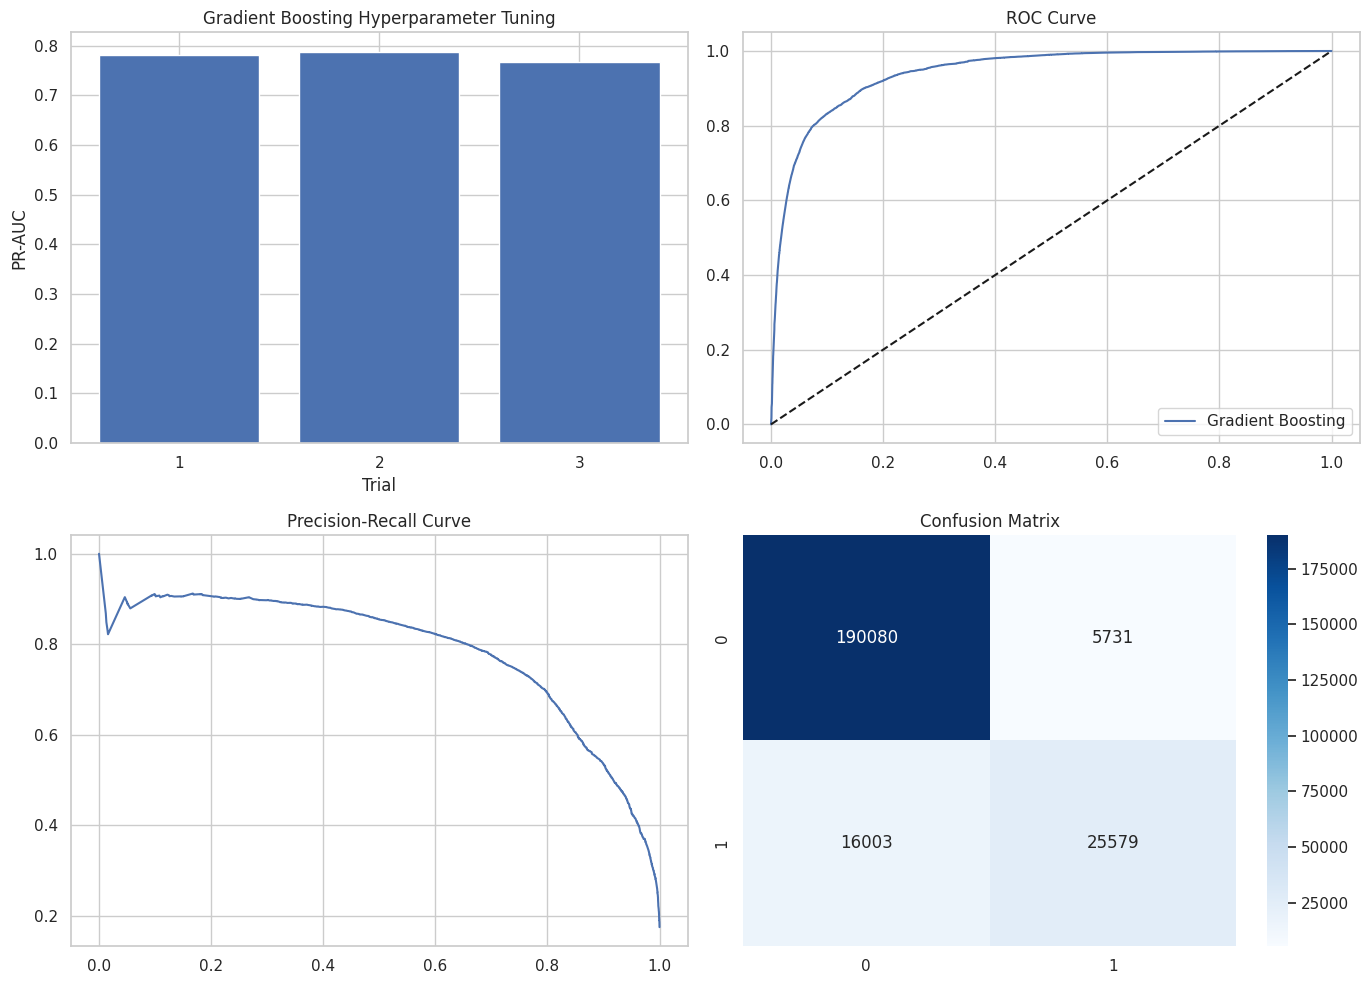

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Hyperparameter comparison
results_df = pd.DataFrame(results)
axes[0, 0].bar(
    results_df["Trial"].astype(str),
    results_df["PR-AUC"]
)
axes[0, 0].set_title("Gradient Boosting Hyperparameter Tuning")
axes[0, 0].set_xlabel("Trial")
axes[0, 0].set_ylabel("PR-AUC")

# ROC curve
fpr, tpr, _ = roc_curve(y_valid, best_probabilities)
axes[0, 1].plot(fpr, tpr, label="Gradient Boosting")
axes[0, 1].plot([0, 1], [0, 1], "k--")
axes[0, 1].set_title("ROC Curve")
axes[0, 1].legend()

# Precision Recall
precision, recall, _ = precision_recall_curve(
    y_valid, best_probabilities
)
axes[1, 0].plot(recall, precision)
axes[1, 0].set_title("Precision-Recall Curve")

# Confusion matrix
sns.heatmap(
    best_metrics["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Confusion Matrix")

plt.tight_layout()
plt.savefig("pathsnap_model_visualizations.png", dpi=200)
plt.show()


## 10. Final held-out student test evaluation

The selected model is not refitted or tuned on this data.

In [11]:
test_predictions = predict_normalized(best_model, train_test)
test_ranking = train_test[["trip_id", "obs_idx", "is_match"]].copy()
test_ranking["raw_probability"] = test_predictions["raw_probability"].to_numpy()
test_ranking_metrics = ranking_metrics(test_ranking)

test_pred = test_predictions["raw_probability"].to_numpy()
test_class = (test_pred >= 0.5).astype(int)
print("=== Student test held-out evaluation ===")
print("Accuracy:", accuracy_score(y_test, test_class))
print("Precision:", precision_score(y_test, test_class, zero_division=0))
print("Recall:", recall_score(y_test, test_class, zero_division=0))
print("Macro F1:", f1_score(y_test, test_class, average="macro", zero_division=0))
print("Weighted F1:", f1_score(y_test, test_class, average="weighted", zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, test_pred))
print("PR-AUC / Average Precision:", average_precision_score(y_test, test_pred))
print("Log Loss:", log_loss(y_test, test_pred, labels=[0, 1]))
print("Top-1 Accuracy:", test_ranking_metrics["Top-1 Accuracy"])
print("Top-3 Recall:", test_ranking_metrics["Top-3 Recall"])
print("MRR:", test_ranking_metrics["MRR"])
print("Normalized probability sum description:")
print(test_predictions.groupby(["trip_id", "obs_idx"])["probability"].sum().describe().to_string())


=== Student test held-out evaluation ===
Accuracy: 0.9206853912736266
Precision: 0.8370572934035884
Recall: 0.6575155865248599
Macro F1: 0.8449095226380114
Weighted F1: 0.9167654215213622
ROC-AUC: 0.9539635876158454
PR-AUC / Average Precision: 0.8350115765950901
Log Loss: 0.21726528016526567
Top-1 Accuracy: 0.8204013202703411
Top-3 Recall: 0.9651595326662126
MRR: 0.8956321555184656
Normalized probability sum description:
count    1.908700e+04
mean     1.000000e+00
std      8.243707e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00


## 11. Export for integration

The export includes the sklearn pipeline, metadata, candidate predictions,
and model comparison. `probability` sums to 1 within each
`(trip_id, obs_idx)` group.

In [12]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

model_path = ARTIFACT_DIR / "pathsnap_best_model.joblib"
metadata_path = ARTIFACT_DIR / "pathsnap_model_metadata.json"
predictions_path = ARTIFACT_DIR / "student_test_candidate_predictions.csv"
comparison_path = ARTIFACT_DIR / "pathsnap_tuned_model_comparison.csv"

joblib.dump(best_model, model_path)
test_predictions.to_csv(predictions_path, index=False)
comparison.to_csv(comparison_path, index=False)

metadata = {
    "selected_model": best_name,
    "feature_columns": FEATURE_COLUMNS,
    "target": TARGET,
    "identifier_columns": IDENTIFIERS,
    "cv_strategy": "GroupKFold",
    "cv_groups": "trip_id",
    "n_splits": n_splits,
    "training_rows": int(len(train)),
    "training_trips": int(groups.nunique()),
    "student_test_rows": int(len(train_test)),
    "probability_format": "raw_probability is binary positive-class probability; probability is normalized within (trip_id, obs_idx)",
    "student_test_ranking": test_ranking_metrics,
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print(model_path)
print(metadata_path)
print(predictions_path)
print(comparison_path)

try:
    from google.colab import files
    for path in [model_path, metadata_path, predictions_path, comparison_path]:
        files.download(str(path))
except ImportError:
    pass


artifacts/pathsnap_best_model.joblib
artifacts/pathsnap_model_metadata.json
artifacts/student_test_candidate_predictions.csv
artifacts/pathsnap_tuned_model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Reusable candidate probability function

In [ ]:
def predict_candidate_probabilities(model, candidate_df):
    # raw_probability is binary positive-class probability.
    # probability sums to 1 within every (trip_id, obs_idx) observation.
    required = set(FEATURE_COLUMNS + IDENTIFIERS)
    missing = sorted(required - set(candidate_df.columns))
    if missing:
        raise ValueError(f"Candidate table missing columns: {missing}")
    return predict_normalized(model, candidate_df)


loaded_model = joblib.load(model_path)
example_predictions = predict_candidate_probabilities(
    loaded_model, train_test.head(100).copy())
example_predictions.head(10)


## 13. Final summary

- Exactly five required model families were trained and tuned.
- Every model used the same feature set and same grouped fold indices.
- Ranking metrics use `(trip_id, obs_idx)` and raw probabilities.
- The student test set was held out from fitting and tuning.
- The exported `probability` field is normalized for HMM emissions.

In [13]:
summary = pd.DataFrame([{
    "Selected model": best_name,
    "CV": f"{n_splits}-fold GroupKFold by trip_id",
    "Training rows": len(train),
    "Training trips": groups.nunique(),
    "OOF Top-1": comparison.iloc[0]["Top-1 Accuracy"],
    "OOF Top-3": comparison.iloc[0]["Top-3 Recall"],
    "OOF MRR": comparison.iloc[0]["MRR"],
    "Student test Top-1": test_ranking_metrics["Top-1 Accuracy"],
    "Student test Top-3": test_ranking_metrics["Top-3 Recall"],
    "Student test MRR": test_ranking_metrics["MRR"],
}])
summary


,Selected model,CV,Training rows,Training trips,OOF Top-1,OOF Top-3,OOF MRR,Student test Top-1,Student test Top-3,Student test MRR
0,Gradient Boosting,5-fold GroupKFold by trip_id,1049122,80,0.778342,0.968159,0.874886,0.820401,0.96516,0.895632
